# 01 · Data Understanding
**Education Insights Lab: Diagnosing Educational Opportunity and Outcomes**

**Purpose of this notebook.** Before cleaning or modelling anything, I want to know *what is in this dataset*: its size, its variable types, what each column means, where values are missing, and which relationships I expect to investigate. Nothing is modified here; this notebook only inspects the raw file.

**Primary research question (full brief in the project README):**
> After accounting for socioeconomic conditions, are per-pupil expenditure and broadband access still associated with mathematics proficiency in US K-12 schools?

**Contents**
1. Load the raw data
2. Size, variable types and column groups
3. Data dictionary
4. Missing values (first look)
5. Quick look at distributions and potential anomalies
6. Target variable
7. Relationships I expect to investigate
8. Summary and hand-off to notebook 02

In [1]:
import sys, warnings
sys.path.append('../src')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from utils import PATHS, set_style, save_fig
set_style()
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

## 1. Load the raw data

In [2]:
df = pd.read_csv(PATHS['raw'])
df.head()

,institution_id,institution_name,state_code,state_name,county,nces_locale,level,control,title_i_status,total_enrollment,number_of_teachers,student_teacher_ratio,percent_free_reduced_lunch,racial_white_pct,racial_black_pct,racial_hispanic_pct,racial_asian_pct,racial_native_pct,racial_two_or_more_pct,special_education_pct,english_learner_pct,per_pupil_expenditure_usd,federal_funding_pct,state_funding_pct,local_funding_pct,math_proficiency_pct,reading_proficiency_pct,graduation_rate_pct,chronic_absenteeism_pct,avg_sat_score,avg_act_score,ap_ib_participation_pct,postsecondary_enrollment_pct,stem_certified_flag,broadband_access_pct
0,US-EDU-10001,Jefferson Elementary School,MA,Massachusetts,Central County,Suburban - Midsize,Elementary School,Public,Title I Schoolwide,447,30,14.8,48.9,70.9,2.4,15.4,8.1,0.1,3.1,14.4,12.9,12840,15.0,54.8,30.2,58.3,58.1,80.9,18.0,NaN,NaN,NaN,NaN,No,91.6
1,US-EDU-10002,Lakeshore Middle School,FL,Florida,Miami-Dade County,Suburban - Midsize,Middle School,Private Religious,Not Applicable,293,29,10.0,1.2,34.7,8.6,36.1,13.3,1.3,6.0,13.7,19.3,17009,0.0,2.0,98.0,84.8,98.0,93.5,17.8,NaN,NaN,NaN,NaN,No,94.4
2,US-EDU-10003,Meadowbrook Elementary Academy,TX,Texas,Bexar County,City - Large,Elementary School,Private For-Profit,Not Applicable,315,17,18.2,36.0,26.2,29.2,22.9,12.3,1.9,7.5,15.7,11.3,15374,10.7,55.5,33.8,54.6,66.2,80.2,19.5,NaN,NaN,NaN,NaN,No,94.0
3,US-EDU-10004,Roosevelt Primary School,FL,Florida,Palm Beach County,Suburban - Large,Elementary School,Public,Not Title I Eligible,389,34,11.3,15.1,49.2,16.7,4.3,26.4,0.1,3.3,13.8,9.8,17065,6.8,38.3,54.9,66.1,70.5,82.1,20.5,NaN,NaN,NaN,NaN,No,96.4
4,US-EDU-10005,Highland Park Primary School,MI,Michigan,Macomb County,Suburban - Large,Elementary School,Public,Title I Targeted,397,29,13.9,45.6,78.1,3.2,8.0,3.9,2.1,4.7,19.8,5.3,16823,15.0,42.3,42.7,54.6,46.7,90.2,19.9,NaN,NaN,NaN,NaN,No,86.3


## 2. Size, variable types and column groups

In [3]:
print(f"Rows:    {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print(f"Memory:  {df.memory_usage(deep=True).sum() / 1e6:.2f} MB")

Rows:    5,000
Columns: 35
Memory:  4.05 MB


In [4]:
id_cols  = ['institution_id', 'institution_name']
cat_cols = [c for c in df.select_dtypes(exclude='number').columns if c not in id_cols]
num_cols = df.select_dtypes(include='number').columns.tolist()

print(f"Identifier / text columns : {len(id_cols)}  -> {id_cols}")
print(f"Categorical columns       : {len(cat_cols)}  -> {cat_cols}")
print(f"Numerical columns         : {len(num_cols)}")

Identifier / text columns : 2  -> ['institution_id', 'institution_name']
Categorical columns       : 8  -> ['state_code', 'state_name', 'county', 'nces_locale', 'level', 'control', 'title_i_status', 'stem_certified_flag']
Numerical columns         : 25


In [5]:
types = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'n_unique': df.nunique(),
    'n_missing': df.isna().sum(),
    'pct_missing': (df.isna().mean() * 100).round(1),
})
types

,dtype,n_unique,n_missing,pct_missing
institution_id,str,5000,0,0.0
institution_name,str,780,0,0.0
state_code,str,51,0,0.0
state_name,str,51,0,0.0
county,str,104,0,0.0
nces_locale,str,8,0,0.0
level,str,6,0,0.0
control,str,5,0,0.0
title_i_status,str,4,0,0.0
total_enrollment,int64,1666,0,0.0


**Reading the table.** `institution_id` has 5,000 unique values, so it is a true unique key. `institution_name` has far fewer unique values than rows, which means names repeat (e.g. several schools with the same generic name). That is not automatically a duplicate problem; I test it properly in notebook 02. Only four columns contain missing values.

## 3. Data dictionary

In [6]:
dictionary = pd.DataFrame([
    # variable, type, description, expected use
    ('institution_id', 'Identifier', 'Unique institution code', 'Key; duplicate check'),
    ('institution_name', 'Text', 'Institution name (not unique)', 'Not used in analysis'),
    ('state_code', 'Categorical', 'Two-letter US state code', 'Geographic context'),
    ('state_name', 'Categorical', 'Full state name', 'Redundant with state_code'),
    ('county', 'Categorical', 'County name (repeats across states)', 'Geographic context; not modelled'),
    ('nces_locale', 'Categorical', 'NCES urban-centric locale (city / suburb / town / rural, by size)', 'Urbanicity; broadband gap'),
    ('level', 'Categorical', 'School level (elementary, middle, high, K-12, 2-year, 4-year)', 'Scope filter; control'),
    ('control', 'Categorical', 'Governance (public, charter, private variants)', 'Control variable'),
    ('title_i_status', 'Categorical', 'Title I classification (schoolwide, targeted, not eligible, N/A)', 'Opportunity / context'),
    ('total_enrollment', 'Numerical', 'Number of enrolled students', 'Institutional size'),
    ('number_of_teachers', 'Numerical', 'Number of teachers', 'Staffing; consistency check'),
    ('student_teacher_ratio', 'Numerical', 'Students per teacher', 'Staffing'),
    ('percent_free_reduced_lunch', 'Numerical', '% of students eligible for free or reduced-price lunch', 'Socioeconomic proxy (key control)'),
    ('racial_white_pct', 'Numerical', '% White students', 'Demographic context'),
    ('racial_black_pct', 'Numerical', '% Black students', 'Demographic context'),
    ('racial_hispanic_pct', 'Numerical', '% Hispanic students', 'Demographic context'),
    ('racial_asian_pct', 'Numerical', '% Asian students', 'Demographic context'),
    ('racial_native_pct', 'Numerical', '% Native American students', 'Demographic context'),
    ('racial_two_or_more_pct', 'Numerical', '% students of two or more races', 'Demographic context'),
    ('special_education_pct', 'Numerical', '% students in special education', 'Student-need control'),
    ('english_learner_pct', 'Numerical', '% English learners', 'Student-need control'),
    ('per_pupil_expenditure_usd', 'Numerical', 'Spending per pupil (US dollars)', 'Key predictor: funding'),
    ('federal_funding_pct', 'Numerical', '% of funding from federal sources', 'Funding mix'),
    ('state_funding_pct', 'Numerical', '% of funding from state sources', 'Funding mix'),
    ('local_funding_pct', 'Numerical', '% of funding from local sources', 'Funding mix'),
    ('math_proficiency_pct', 'Numerical', '% of students proficient in mathematics', 'TARGET (academic outcome)'),
    ('reading_proficiency_pct', 'Numerical', '% of students proficient in reading', 'Outcome; excluded from predictors'),
    ('graduation_rate_pct', 'Numerical', 'Graduation rate (%)', 'Outcome; meaningful for high schools only'),
    ('chronic_absenteeism_pct', 'Numerical', '% of students chronically absent', 'Outcome / pathway; excluded from predictors'),
    ('avg_sat_score', 'Numerical', 'Average SAT score', 'Postsecondary indicator (structurally missing)'),
    ('avg_act_score', 'Numerical', 'Average ACT score', 'Postsecondary indicator (structurally missing)'),
    ('ap_ib_participation_pct', 'Numerical', '% participating in AP / IB courses', 'Postsecondary indicator (structurally missing)'),
    ('postsecondary_enrollment_pct', 'Numerical', '% enrolling in postsecondary education', 'Postsecondary indicator (structurally missing)'),
    ('stem_certified_flag', 'Categorical (binary)', 'Yes / No: STEM certified', 'STEM readiness; context'),
    ('broadband_access_pct', 'Numerical', '% of students with broadband access', 'Key predictor: technology access'),
], columns=['variable', 'type', 'description', 'expected_use'])

# Safety check: the dictionary must cover every column in the file exactly once.
assert set(dictionary['variable']) == set(df.columns), 'Dictionary does not match the dataset columns'
assert dictionary['variable'].is_unique

PATHS['docs'].mkdir(exist_ok=True)
dictionary.to_csv(PATHS['docs'] / 'data_dictionary.csv', index=False)
dictionary

,variable,type,description,expected_use
0,institution_id,Identifier,Unique institution code,Key; duplicate check
1,institution_name,Text,Institution name (not unique),Not used in analysis
2,state_code,Categorical,Two-letter US state code,Geographic context
3,state_name,Categorical,Full state name,Redundant with state_code
4,county,Categorical,County name (repeats across states),Geographic context; not modelled
5,nces_locale,Categorical,NCES urban-centric locale (city / suburb / tow...,Urbanicity; broadband gap
6,level,Categorical,"School level (elementary, middle, high, K-12, ...",Scope filter; control
7,control,Categorical,"Governance (public, charter, private variants)",Control variable
8,title_i_status,Categorical,"Title I classification (schoolwide, targeted, ...",Opportunity / context
9,total_enrollment,Numerical,Number of enrolled students,Institutional size


> The dictionary is saved to `docs/data_dictionary.csv`. The assertion above guarantees that it covers all 35 columns, so I cannot accidentally leave one undocumented. Descriptions are my interpretation of the column names; where the exact definition matters (for example how "proficiency" is measured), that is listed as a limitation in the README.

## 4. Missing values (first look)

In [7]:
missing = df.isna().sum()
missing = missing[missing > 0].to_frame('n_missing')
missing['pct_missing'] = (missing['n_missing'] / len(df) * 100).round(1)
missing

,n_missing,pct_missing
avg_sat_score,3375,67.5
avg_act_score,3375,67.5
ap_ib_participation_pct,3579,71.6
postsecondary_enrollment_pct,3579,71.6


Four columns have missing values, and they come in matching pairs: SAT and ACT share the same count, and AP/IB and postsecondary enrollment share the same count. Identical counts in different columns are a strong hint that the missingness is **structural** (tied to something about the institution) rather than random. I check which institutions are affected:

,avg_sat_score,avg_act_score,ap_ib_participation_pct,postsecondary_enrollment_pct
level,,,,
2-Year College,100.0,100.0,100.0,100.0
4-Year University,0.0,0.0,100.0,100.0
Elementary School,100.0,100.0,100.0,100.0
High School,0.0,0.0,0.0,0.0
K-12 Combined,0.0,0.0,0.0,0.0
Middle School,100.0,100.0,100.0,100.0


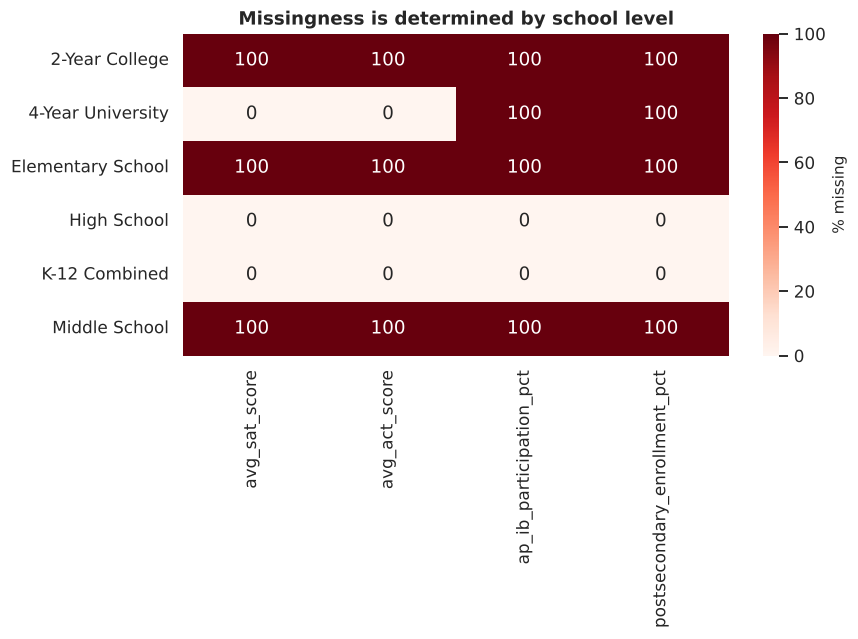

In [8]:
miss_cols = ['avg_sat_score', 'avg_act_score', 'ap_ib_participation_pct', 'postsecondary_enrollment_pct']

pct_missing_by_level = (
    df.groupby('level')[miss_cols]
      .agg(lambda s: s.isna().mean() * 100)
      .round(1)
)
display(pct_missing_by_level)

plt.figure(figsize=(8, 3.8))
sns.heatmap(pct_missing_by_level, annot=True, fmt='.0f', cmap='Reds', vmin=0, vmax=100,
            cbar_kws={'label': '% missing'})
plt.title('Missingness is determined by school level')
plt.ylabel('')
save_fig('01_missingness_by_level')
plt.show()

**Finding.** Each of these columns is either **100% missing or 0% missing** within a school level. Elementary schools, middle schools and 2-year colleges have no SAT/ACT values; elementary schools, middle schools, 2-year colleges *and* 4-year universities have no AP/IB or postsecondary-enrollment values. This is not random noise. These metrics simply do not exist for those kinds of institution (an elementary school has no SAT average). I will treat this carefully in notebook 02 rather than filling the gaps.

## 5. Quick look at distributions and potential anomalies

In [9]:
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
total_enrollment,5000.0,1375.88,3416.62,80.0,438.0,603.00,914.0,45252.0
number_of_teachers,5000.0,92.46,225.93,5.0,29.0,42.00,66.0,3279.0
student_teacher_ratio,5000.0,14.93,3.33,6.0,12.6,14.90,17.1,30.0
percent_free_reduced_lunch,5000.0,41.28,24.09,0.0,21.7,42.40,59.5,98.0
racial_white_pct,5000.0,48.08,19.63,3.9,33.0,48.85,63.9,92.1
racial_black_pct,5000.0,17.42,11.82,0.8,8.4,15.40,24.5,67.3
racial_hispanic_pct,5000.0,21.17,12.41,1.5,11.5,19.90,29.1,83.2
racial_asian_pct,5000.0,7.75,6.02,0.3,2.8,6.40,11.6,36.0
racial_native_pct,5000.0,1.44,1.34,0.1,0.2,1.20,2.2,9.6
racial_two_or_more_pct,5000.0,4.13,2.11,0.5,2.6,3.90,5.3,25.4


In [10]:
print('Value counts for each categorical variable:\n')
for c in ['level', 'control', 'title_i_status', 'nces_locale', 'stem_certified_flag']:
    print(c)
    print(df[c].value_counts().to_string())
    print()

Value counts for each categorical variable:

level
level
Elementary School    2225
High School          1209
Middle School         996
K-12 Combined         212
4-Year University     204
2-Year College        154

control
control
Public                3547
Public Charter         577
Private Non-Profit     499
Private Religious      256
Private For-Profit     121

title_i_status
title_i_status
Title I Schoolwide      2180
Not Applicable          1108
Title I Targeted         945
Not Title I Eligible     767

nces_locale
nces_locale
Suburban - Large      1496
City - Large          1090
Suburban - Midsize     643
City - Midsize         541
Town - Fringe          395
Rural - Fringe         318
Rural - Remote         270
Town - Distant         247

stem_certified_flag
stem_certified_flag
No     4248
Yes     752



**Things that already look worth investigating (all tested in notebook 02):**
- `total_enrollment` ranges from tiny schools to very large institutions, so it is probably heavily right-skewed.
- `per_pupil_expenditure_usd` has a long upper tail (a maximum far above the typical value).
- `graduation_rate_pct` has no missing values at all, even for elementary and middle schools, which do not graduate students. That looks suspicious.
- Some columns pile up at one exact value (for example `local_funding_pct` at 98 and `reading_proficiency_pct` at its maximum). I need to find out whether these are reporting caps or a structural pattern.
- Race percentages and funding-source percentages should each sum to 100; I will verify this.
- `student_teacher_ratio` should equal `total_enrollment / number_of_teachers`; I will verify this too.
- 2-year colleges and 4-year universities are a very different population from K-12 schools (they have no Title I status, for instance), so they may not belong in the same analysis.

## 6. Target variable

count    5000.00
mean       60.01
std        16.55
min        12.00
25%        48.20
50%        60.10
75%        71.80
max        96.00
Name: math_proficiency_pct, dtype: float64

Skewness: -0.03


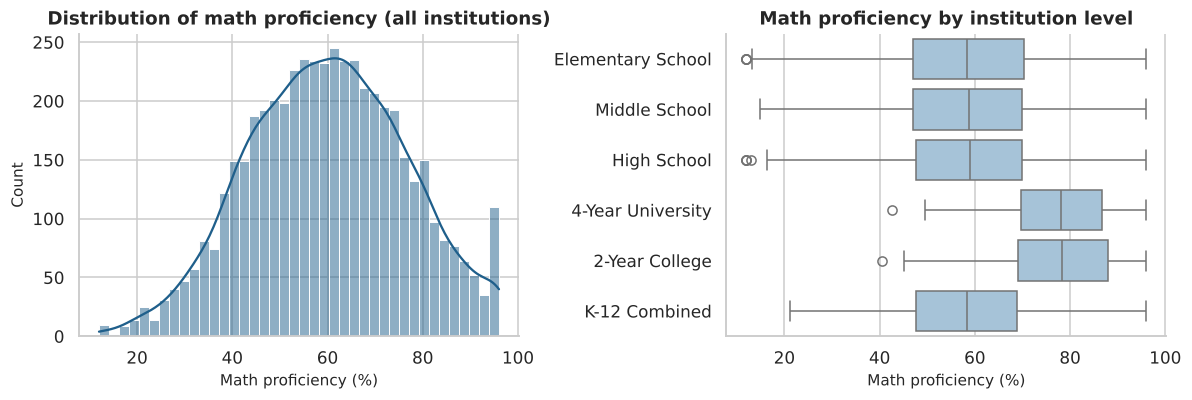

In [11]:
target = 'math_proficiency_pct'
print(df[target].describe().round(2))
print(f"\nSkewness: {df[target].skew():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df[target], bins=40, kde=True, ax=ax[0], color='#1f5f8b')
ax[0].set_title('Distribution of math proficiency (all institutions)')
ax[0].set_xlabel('Math proficiency (%)')
sns.boxplot(data=df, y='level', x=target, ax=ax[1], color='#9ec5e0')
ax[1].set_title('Math proficiency by institution level')
ax[1].set_xlabel('Math proficiency (%)'); ax[1].set_ylabel('')
plt.tight_layout()
save_fig('01_target_distribution')
plt.show()

**Why `math_proficiency_pct` is my target.**
- It is available for **every** institution (no missing values), so no observations are lost.
- It is a direct academic-outcome measure that is continuous and roughly symmetric, which suits regression modelling.
- Mathematics outcomes are widely used in funding and equity debates, which fits the stakeholder scenario in the README.

The plot also shows that colleges and universities sit at a visibly different level from K-12 schools, which supports restricting the analysis to K-12 (decided formally in notebook 02).

## 7. Relationships I expect to investigate

In [12]:
hypotheses = pd.DataFrame([
    ('H1', 'percent_free_reduced_lunch', 'math_proficiency_pct', 'Negative', 'Higher poverty -> lower proficiency (the strongest expected relationship)'),
    ('H2', 'per_pupil_expenditure_usd', 'math_proficiency_pct', 'Positive', 'More spending -> higher proficiency, but partly because richer areas spend more'),
    ('H3', 'broadband_access_pct', 'math_proficiency_pct', 'Positive', 'Better access -> higher proficiency, but access is also linked to poverty'),
    ('H4', 'student_teacher_ratio', 'math_proficiency_pct', 'Negative (weak)', 'Larger classes -> slightly lower proficiency'),
    ('H5', 'title_i_status', 'math_proficiency_pct', 'Differences by group', 'Title I schools serve poorer students, so lower average proficiency'),
    ('H6', 'nces_locale', 'broadband_access_pct', 'Differences by group', 'Rural / remote institutions may have lower broadband access'),
    ('H7', 'poverty (control)', 'spending & broadband effects', 'Confounding', 'Poverty may explain part (or all) of the raw spending and broadband links to outcomes'),
], columns=['id', 'predictor', 'outcome', 'expected_direction', 'reasoning'])
hypotheses

,id,predictor,outcome,expected_direction,reasoning
0,H1,percent_free_reduced_lunch,math_proficiency_pct,Negative,Higher poverty -> lower proficiency (the stron...
1,H2,per_pupil_expenditure_usd,math_proficiency_pct,Positive,"More spending -> higher proficiency, but partl..."
2,H3,broadband_access_pct,math_proficiency_pct,Positive,"Better access -> higher proficiency, but acces..."
3,H4,student_teacher_ratio,math_proficiency_pct,Negative (weak),Larger classes -> slightly lower proficiency
4,H5,title_i_status,math_proficiency_pct,Differences by group,"Title I schools serve poorer students, so lowe..."
5,H6,nces_locale,broadband_access_pct,Differences by group,Rural / remote institutions may have lower bro...
6,H7,poverty (control),spending & broadband effects,Confounding,Poverty may explain part (or all) of the raw s...


The most important idea behind the whole project is **H7**: a raw correlation between spending (or broadband) and math scores can be misleading if poverty drives both. That is why the analysis uses multivariate methods and not only two-variable comparisons.

## 8. Summary and hand-off

| Item | Finding |
|---|---|
| Size | 5,000 rows × 35 columns, one row per institution |
| Unique key | `institution_id` (unique); names repeat |
| Types | 2 identifier/text, 8 categorical (incl. binary STEM flag), 25 numerical |
| Missing values | Only SAT, ACT, AP/IB, postsecondary; **structural** (depends on level), not random |
| Target | `math_proficiency_pct` (complete, continuous) |
| Scope question | Colleges/universities look different from K-12 schools |
| Suspicious items to test | Graduation rate for elementary schools; ceilings; ratio consistency; outliers; name repeats |

**Next → `02_data_cleaning.ipynb`:** investigate each of those issues, decide what to remove, retain or flag, justify each decision, and produce the cleaned datasets.